# 03 — Cats vs Dogs (CIFAR-10 binary, Transfer Learning)

This notebook builds a binary classifier using pretrained ResNet18 on CIFAR-10
(cat = class 3, dog = class 5).  Only the final FC layer is replaced — the
backbone weights are frozen for speed.

Topics covered:
- **Transfer learning** — reuse ImageNet features, fine-tune only the head
- **Binary cross-entropy loss** — one output neuron with sigmoid
- **Grad-CAM** — adapted for a binary task (single output)
- **Embedding PCA** — penultimate 512-d features coloured by cat/dog
- **Error analysis** — hardest confusions

**Run all cells top-to-bottom.** No prior image_nets notebook is required.

> **Kernel:** `source /root/LLM/venv/bin/activate && jupyter notebook --notebook-dir=image_nets/notebooks`

**What we do:** Imports, seeds, `FORCE_CPU` flag, artifact paths.
**Why:** All configuration in one place.
**What you should see:** No output.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path().resolve().parent))

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import json
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset

FORCE_CPU  = False
SEED       = 42
BATCH_SIZE = 64
EPOCHS     = 5
LR         = 1e-3
VAL_FRAC   = 0.1

CAT_CLS = 3   # CIFAR-10 class index for 'cat'
DOG_CLS = 5   # CIFAR-10 class index for 'dog'
CLASS_NAMES = ["cat", "dog"]

torch.manual_seed(SEED)
np.random.seed(SEED)

NOTEBOOK_DIR  = pathlib.Path().resolve()
ARTIFACTS_DIR = NOTEBOOK_DIR.parent / "artifacts"
DATA_DIR      = ARTIFACTS_DIR / "cifar10_data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

**What we do:** Detect compute device.
**Why:** Same pattern as all other notebooks — GPU if available, else CPU.
**What you should see:** `cuda` or `cpu`.

In [2]:
if FORCE_CPU:
    device = torch.device("cpu")
elif torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"GPU : {torch.cuda.get_device_name(0)}")
else:
    device = torch.device("cpu")

print(f"device : {device}")

GPU : NVIDIA GeForce RTX 2050
device : cuda


**What we do:** Download CIFAR-10, filter to cats and dogs only, split into
train / val / test (80% / 10% / 10% of the cat+dog pool).
**Why:** We need only 2 of the 10 CIFAR-10 classes. ImageNet-pretrained models
expect 3-channel 224×224 input; we resize and normalise to match.
**What you should see:** Train / val / test counts, roughly 5000 / 500 / 500 each.

In [3]:
imagenet_mean = (0.485, 0.456, 0.406)
imagenet_std  = (0.229, 0.224, 0.225)

train_tf = transforms.Compose([
    transforms.Resize(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])
eval_tf = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

cifar_full = datasets.CIFAR10(DATA_DIR, train=True,  download=True, transform=train_tf)
cifar_test = datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=eval_tf)

def catdog_indices(dataset):
    targets = np.array(dataset.targets)
    return np.where((targets == CAT_CLS) | (targets == DOG_CLS))[0].tolist()

train_idx = catdog_indices(cifar_full)
test_idx  = catdog_indices(cifar_test)

rng = np.random.default_rng(SEED)
rng.shuffle(train_idx)
n_val   = int(len(train_idx) * VAL_FRAC)
val_idx = train_idx[:n_val]
tr_idx  = train_idx[n_val:]

class RelabelSubset(torch.utils.data.Dataset):
    def __init__(self, base, indices):
        self.base    = base
        self.indices = indices
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        img, lbl = self.base[self.indices[i]]
        return img, 0 if lbl == CAT_CLS else 1

train_set = RelabelSubset(cifar_full, tr_idx)
val_set   = RelabelSubset(cifar_full, val_idx)
test_set  = RelabelSubset(cifar_test, test_idx)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"train  : {len(train_set):>5,}")
print(f"val    : {len(val_set):>5,}")
print(f"test   : {len(test_set):>5,}")

assert abs(len(val_set) / (len(train_set) + len(val_set)) - VAL_FRAC) < 0.02, "FAIL: val split"
print("PASS: dataset split correct")

train  : 9,000
val    : 1,000
test   : 2,000
PASS: dataset split correct


**What we do:** Plot 16 random training images.
**Why:** Cats and dogs from CIFAR-10 are much harder than MNIST digits — 32×32
colour images, diverse poses and backgrounds. Looking at them sets realistic
expectations for accuracy.
**What you should see:** 16 small colour images labelled 'cat' or 'dog'.

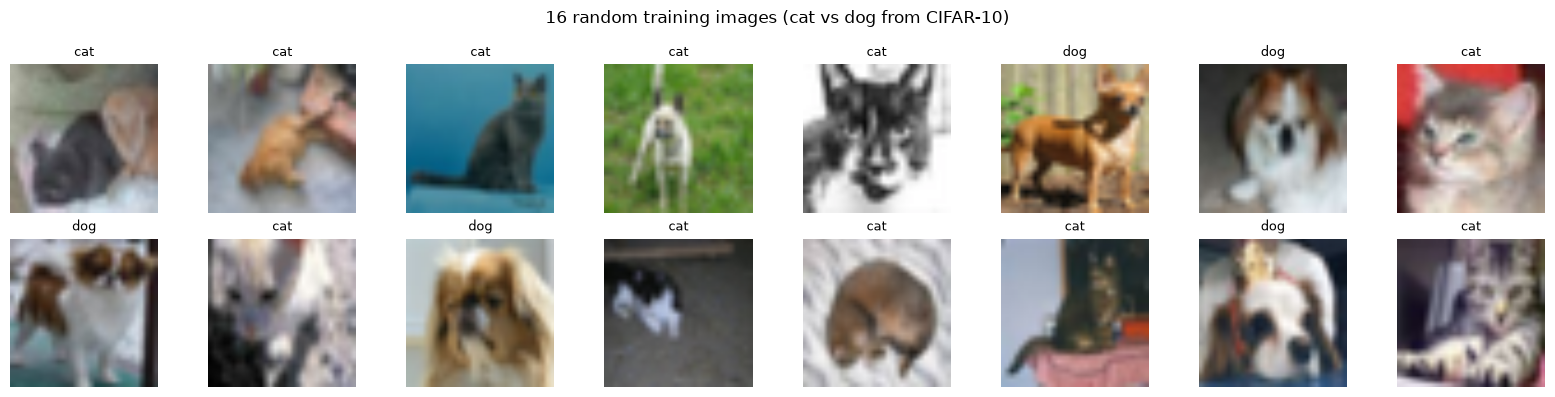

In [4]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
rng_plt = np.random.default_rng(SEED + 1)
idxs = rng_plt.choice(len(train_set), 16, replace=False)

for ax, idx in zip(axes.flat, idxs):
    img_t, lbl = train_set[int(idx)]
    # undo normalisation for display
    mean = torch.tensor(imagenet_mean).view(3,1,1)
    std  = torch.tensor(imagenet_std).view(3,1,1)
    img  = (img_t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
    ax.imshow(img)
    ax.set_title(CLASS_NAMES[lbl], fontsize=9)
    ax.axis("off")

fig.suptitle("16 random training images (cat vs dog from CIFAR-10)")
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "catdog_samples.png", dpi=100, bbox_inches="tight")
plt.show()

**What we do:** Load pretrained ResNet18 and replace only the final FC layer
with a single output neuron (binary logit).  Freeze all backbone parameters.
**Why:** ResNet18 pretrained on ImageNet already knows edges, textures, shapes.
Cats and dogs share these features — we only need to teach the network *which*
combination signals 'cat' vs 'dog'.  Freezing the backbone makes training fast
(only 513 parameters are updated).
**What you should see:** Model summary, parameter counts (frozen vs trainable).

In [5]:
backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

for p in backbone.parameters():
    p.requires_grad = False

backbone.fc = nn.Linear(backbone.fc.in_features, 1)

model = backbone.to(device)

n_total     = sum(p.numel() for p in model.parameters())
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total params    : {n_total:,}")
print(f"Trainable params: {n_trainable:,}  (frozen: {n_total - n_trainable:,})")

assert n_trainable == backbone.fc.weight.numel() + backbone.fc.bias.numel(), "FAIL: freeze"
print("PASS: only FC layer is trainable")

Total params    : 11,177,025
Trainable params: 513  (frozen: 11,176,512)
PASS: only FC layer is trainable


**What we do:** Verify the forward pass produces a scalar logit per image.
**Why:** With BCE loss we need shape (B,) or (B,1); a shape error here surfaces
before training starts.
**What you should see:** `output shape: torch.Size([4, 1])` and PASS.

In [6]:
dummy = torch.randn(4, 3, 224, 224).to(device)
model.eval()
with torch.no_grad():
    out = model(dummy)

print(f"output shape : {out.shape}")
assert out.shape == (4, 1), f"FAIL: {out.shape}"
print("PASS: forward pass shape correct")

output shape : torch.Size([4, 1])
PASS: forward pass shape correct


**What we do:** Train for `EPOCHS` epochs with BCEWithLogitsLoss and Adam.
Record train loss, val loss, val accuracy each epoch.
**Why:** Fine-tuning a frozen ResNet18 head converges in 3–5 epochs — fast
even on a small GPU.
**What you should see:** Val accuracy climbing above 75% within 2 epochs.

In [7]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LR)

history = {"train_loss": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0
best_epoch   = 0

model.train()
for epoch in range(1, EPOCHS + 1):
    # ── train ──────────────────────────────────────────────────────────────
    model.train()
    running_loss = 0.0
    for X, y in train_loader:
        X, y = X.to(device), y.float().unsqueeze(1).to(device)
        optimizer.zero_grad()
        loss = criterion(model(X), y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(X)
    train_loss = running_loss / len(train_set)

    # ── val ────────────────────────────────────────────────────────────────
    model.eval()
    val_loss_sum, correct = 0.0, 0
    with torch.no_grad():
        for X, y in val_loader:
            X, y = X.to(device), y.float().unsqueeze(1).to(device)
            logits = model(X)
            val_loss_sum += criterion(logits, y).item() * len(X)
            correct += ((logits.sigmoid() > 0.5) == y.bool()).sum().item()
    val_loss = val_loss_sum / len(val_set)
    val_acc  = correct / len(val_set)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch   = epoch
        torch.save({"epoch": epoch, "model_state": model.state_dict(),
                    "val_acc": val_acc},
                   ARTIFACTS_DIR / "catdog_best.pt")

    print(f"epoch {epoch}/{EPOCHS}  train_loss={train_loss:.4f}  "
          f"val_loss={val_loss:.4f}  val_acc={val_acc:.4f}")

print(f"\nBest val acc {best_val_acc:.4f} at epoch {best_epoch}")
assert best_val_acc > 0.70, f"FAIL: val acc {best_val_acc:.4f} < 0.70"
print("PASS: training complete")

epoch 1/5  train_loss=0.5316  val_loss=0.4404  val_acc=0.7960


epoch 2/5  train_loss=0.4121  val_loss=0.3947  val_acc=0.8250


epoch 3/5  train_loss=0.3819  val_loss=0.3718  val_acc=0.8400


epoch 4/5  train_loss=0.3726  val_loss=0.3725  val_acc=0.8290


epoch 5/5  train_loss=0.3665  val_loss=0.3531  val_acc=0.8420

Best val acc 0.8420 at epoch 5
PASS: training complete


**What we do:** Plot training and validation loss + val accuracy curves.
**Why:** Confirms the model is learning and not over-fitting in 5 epochs.
**What you should see:** Both losses falling; val accuracy rising toward 75–80%.

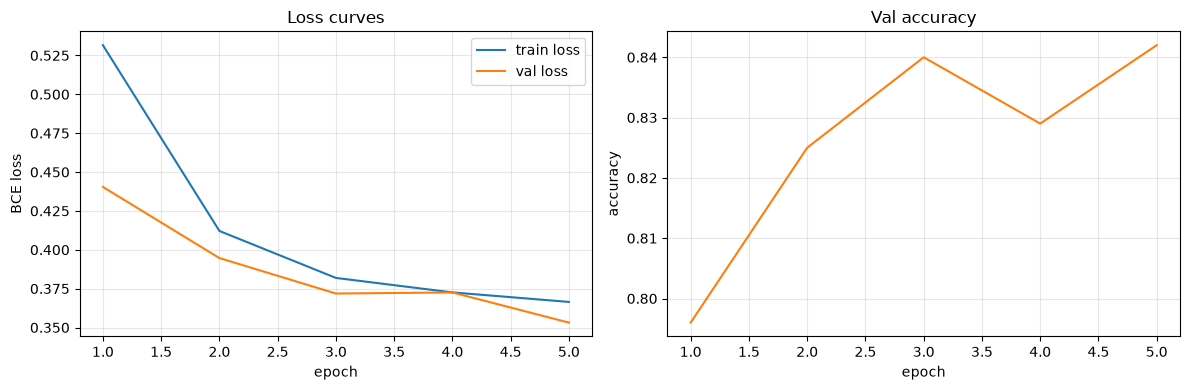

In [8]:
epochs_x = range(1, len(history["train_loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs_x, history["train_loss"], label="train loss")
ax1.plot(epochs_x, history["val_loss"],   label="val loss")
ax1.set_xlabel("epoch"); ax1.set_ylabel("BCE loss")
ax1.set_title("Loss curves"); ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(epochs_x, history["val_acc"], color="tab:orange")
ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy")
ax2.set_title("Val accuracy"); ax2.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "catdog_curves.png", dpi=100, bbox_inches="tight")
plt.show()

**What we do:** Score on the held-out test set exactly once.
**Why:** The test score is the final reported accuracy — it must not influence
any training decision.
**What you should see:** Test accuracy in a similar range to val accuracy.

In [9]:
_test_scored_catdog = 0

def score_test_once():
    global _test_scored_catdog
    assert _test_scored_catdog == 0, "FAIL: test set scored more than once"
    _test_scored_catdog += 1

    ckpt = torch.load(ARTIFACTS_DIR / "catdog_best.pt",
                      map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state"])
    model.eval()

    correct = 0
    with torch.no_grad():
        for X, y in test_loader:
            X, y = X.to(device), y.float().unsqueeze(1).to(device)
            correct += ((model(X).sigmoid() > 0.5) == y.bool()).sum().item()
    acc = correct / len(test_set)
    print(f"Test accuracy  : {acc:.4f}  ({correct}/{len(test_set)})")
    assert acc > 0.70, f"FAIL: test acc {acc:.4f} < 0.70"
    print("PASS: test scored")
    return acc

test_acc = score_test_once()

Test accuracy  : 0.8340  (1668/2000)
PASS: test scored


**What we do:** Apply Grad-CAM adapted for binary classification — gradient of
the single output logit w.r.t. the last ResNet block (`layer4`).
**Why:** Grad-CAM on a binary model uses the same formula as multi-class, but
there is only one class score to differentiate. The heatmap should highlight
the animal's face and body, not background clutter.
**What you should see:** 8 rows of (image | heatmap | overlay).

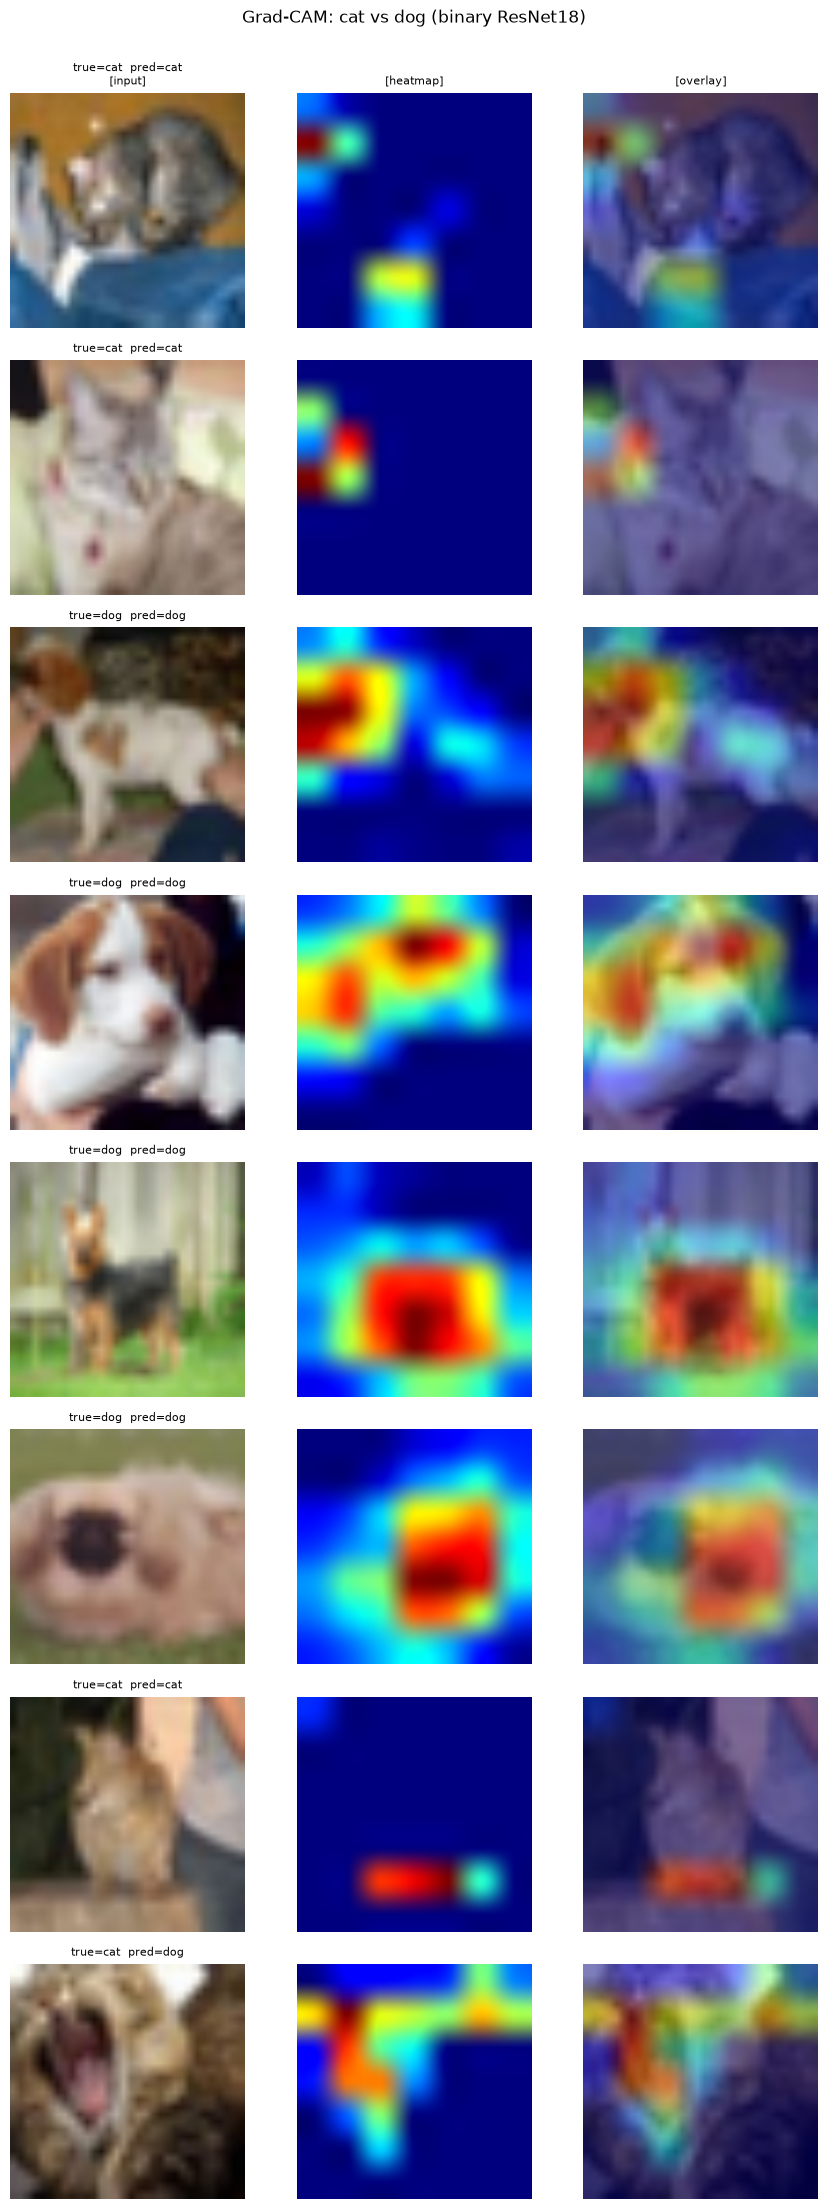

In [10]:
import torch.nn.functional as F_nn
import numpy as _np
import PIL.Image

def gradcam_binary(model, img_t, device):
    model.eval()
    features, gradients = {}, {}

    def fwd_hook(m, inp, out): features["x"] = out
    def bwd_hook(m, gi, go):   gradients["x"] = go[0]

    target = model.layer4
    h_f = target.register_forward_hook(fwd_hook)
    h_b = target.register_full_backward_hook(bwd_hook)

    inp = img_t.unsqueeze(0).to(device).float()
    inp.requires_grad_(True)
    logit = model(inp)
    model.zero_grad()
    logit.backward()

    h_f.remove(); h_b.remove()

    feat = features["x"].detach().squeeze(0)
    grad = gradients["x"].detach().squeeze(0)
    weights = grad.mean(dim=(1, 2))
    cam = (weights[:, None, None] * feat).sum(0).relu()
    cam = cam.cpu().numpy()
    cam -= cam.min(); cam /= cam.max() + 1e-8
    return cam

samples, sample_labels = [], []
counts = {0: 0, 1: 0}
for img, lbl in test_set:
    if counts[lbl] < 4:
        samples.append(img); sample_labels.append(lbl); counts[lbl] += 1
    if counts[0] == 4 and counts[1] == 4:
        break

mean_t = torch.tensor(imagenet_mean).view(3,1,1)
std_t  = torch.tensor(imagenet_std).view(3,1,1)

fig, axes = plt.subplots(8, 3, figsize=(9, 22))
for row, (img_t, lbl) in enumerate(zip(samples, sample_labels)):
    cam = gradcam_binary(model, img_t, device)

    img_disp = (img_t * std_t + mean_t).clamp(0,1).permute(1,2,0).numpy()
    H, W = img_disp.shape[:2]

    heatmap    = plt.cm.jet(cam)[:, :, :3]
    heatmap_rs = _np.array(
        PIL.Image.fromarray((heatmap * 255).astype(_np.uint8)).resize((W, H))
    ) / 255
    overlay = (0.5 * img_disp + 0.5 * heatmap_rs).clip(0, 1)

    with torch.no_grad():
        pred_lbl = int(model(img_t.unsqueeze(0).to(device)).item() > 0)

    axes[row, 0].imshow(img_disp);  axes[row, 0].axis("off")
    axes[row, 1].imshow(heatmap_rs); axes[row, 1].axis("off")
    axes[row, 2].imshow(overlay);   axes[row, 2].axis("off")
    axes[row, 0].set_title(
        f"true={CLASS_NAMES[lbl]}  pred={CLASS_NAMES[pred_lbl]}", fontsize=8)

for col, title in enumerate(["input", "heatmap", "overlay"]):
    axes[0, col].set_title(axes[0, col].get_title() + f"\n[{title}]", fontsize=8)

fig.suptitle("Grad-CAM: cat vs dog (binary ResNet18)", y=1.002)
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "catdog_gradcam.png", dpi=100, bbox_inches="tight")
plt.show()

**What we do:** Extract the 512-dimensional penultimate embedding (avgpool output)
for all test images, reduce to 2D with PCA, colour by cat/dog.
**Why:** The ResNet backbone maps each image to a 512-d vector. If transfer
learning worked, cat vectors and dog vectors should form distinct clusters
even though the backbone was trained on 1000 ImageNet classes.
**What you should see:** Two clouds of points, one per class, with some overlap.

Embedding shape : (2000, 512)
PCA variance: PC1=0.037  PC2=0.033


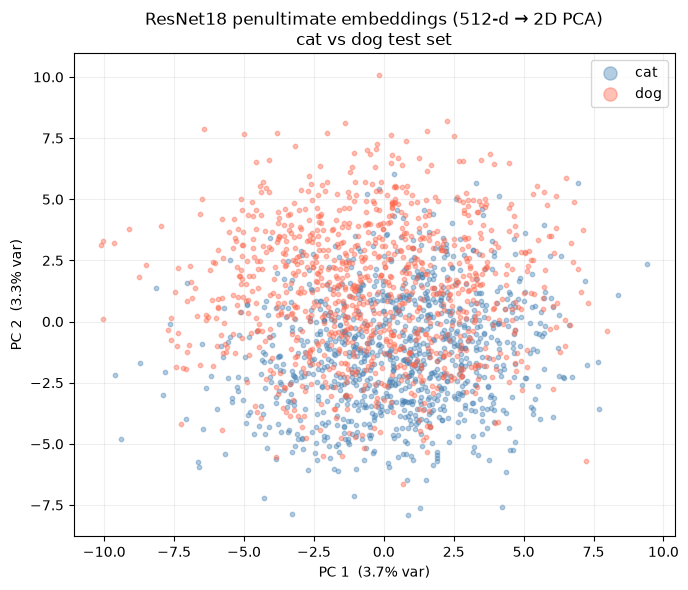

In [11]:
from sklearn.decomposition import PCA

embs, labels_list = [], []
store_e = {}

h = model.avgpool.register_forward_hook(
    lambda m,i,o: store_e.update({"e": o.detach().squeeze(-1).squeeze(-1).cpu()})
)

model.eval()
with torch.no_grad():
    for X, y in test_loader:
        _ = model(X.to(device))
        embs.append(store_e["e"].numpy())
        labels_list.extend(y.numpy())

h.remove()

E = np.vstack(embs)
L = np.array(labels_list)

pca = PCA(n_components=2, random_state=SEED)
E2  = pca.fit_transform(E)
var = pca.explained_variance_ratio_

print(f"Embedding shape : {E.shape}")
print(f"PCA variance: PC1={var[0]:.3f}  PC2={var[1]:.3f}")

colors = ["steelblue", "tomato"]
fig, ax = plt.subplots(figsize=(7, 6))
for cls, name in enumerate(CLASS_NAMES):
    mask = L == cls
    ax.scatter(E2[mask, 0], E2[mask, 1], s=10, alpha=0.4,
               color=colors[cls], label=name)

ax.legend(markerscale=3, fontsize=10)
ax.set_xlabel(f"PC 1  ({var[0]*100:.1f}% var)")
ax.set_ylabel(f"PC 2  ({var[1]*100:.1f}% var)")
ax.set_title("ResNet18 penultimate embeddings (512-d → 2D PCA)\ncat vs dog test set")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "catdog_embedding_pca.png", dpi=100, bbox_inches="tight")
plt.show()

**What we do:** Find the 12 test images the model was most wrong about
(highest BCE loss among misclassified samples).
**Why:** Error analysis reveals *what kinds* of cats or dogs fool the model —
unusual angles, occlusion, high background contrast. This is the feedback loop
for improving the model.
**What you should see:** 12 images where the model is confidently wrong.

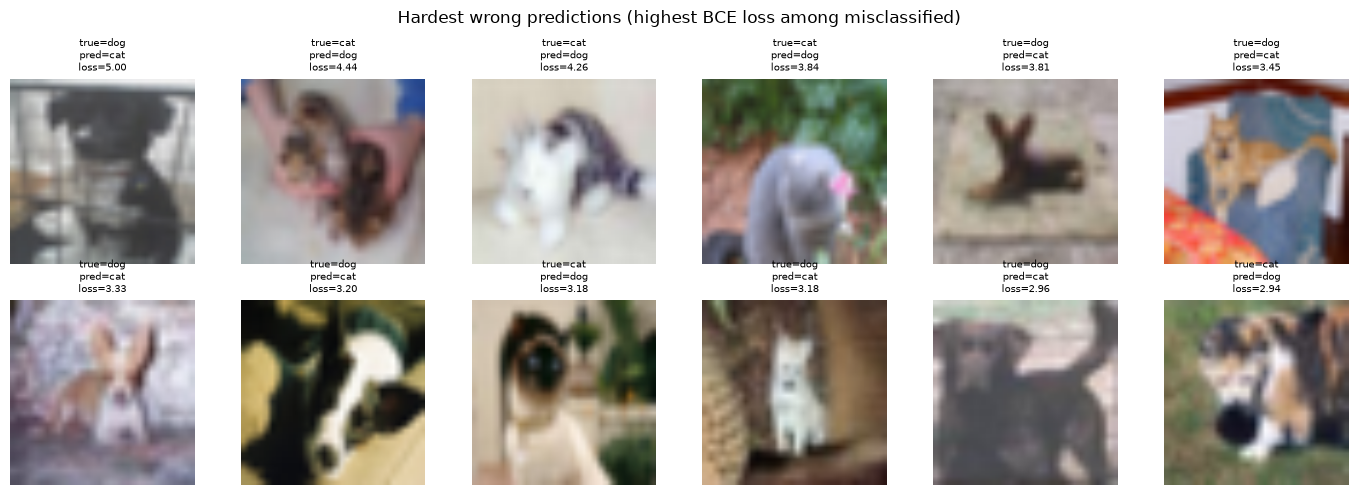

In [12]:
losses_all, preds_all, imgs_all, labs_all = [], [], [], []

model.eval()
with torch.no_grad():
    for X, y in test_loader:
        X_d = X.to(device)
        y_f = y.float().unsqueeze(1).to(device)
        logits = model(X_d)
        loss_per = F_nn.binary_cross_entropy_with_logits(logits, y_f, reduction="none").squeeze(1)
        preds = (logits.sigmoid() > 0.5).long().squeeze(1)
        losses_all.append(loss_per.cpu())
        preds_all.append(preds.cpu())
        imgs_all.append(X.cpu())
        labs_all.append(y)

losses_all = torch.cat(losses_all).numpy()
preds_all  = torch.cat(preds_all).numpy()
imgs_all   = torch.cat(imgs_all)
labs_all   = torch.cat(labs_all).numpy()

wrong_mask = preds_all != labs_all
wrong_idx  = np.where(wrong_mask)[0]
top12 = wrong_idx[np.argsort(losses_all[wrong_mask])[::-1][:12]]

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, idx in zip(axes.flat, top12):
    img_t = imgs_all[idx]
    img   = (img_t * std_t + mean_t).clamp(0,1).permute(1,2,0).numpy()
    ax.imshow(img)
    ax.set_title(
        f"true={CLASS_NAMES[labs_all[idx]]}\npred={CLASS_NAMES[preds_all[idx]]}\n"
        f"loss={losses_all[idx]:.2f}", fontsize=7)
    ax.axis("off")

fig.suptitle("Hardest wrong predictions (highest BCE loss among misclassified)")
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "catdog_errors.png", dpi=100, bbox_inches="tight")
plt.show()